In [20]:
from pathlib import Path
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import folium
import contextily as cx
from shapely import box

In [24]:
nl_path = Path('../data/outputs/netherlands.gpkg')
n_hoods_path = Path('/home/lorem/Data/WijkBuurtkaart_2026_v0.gpkg')

map_export_path = Path('../web/maps')
image_export_path = Path('../web/images')

cities = gpd.read_file(nl_path, layer='cities')

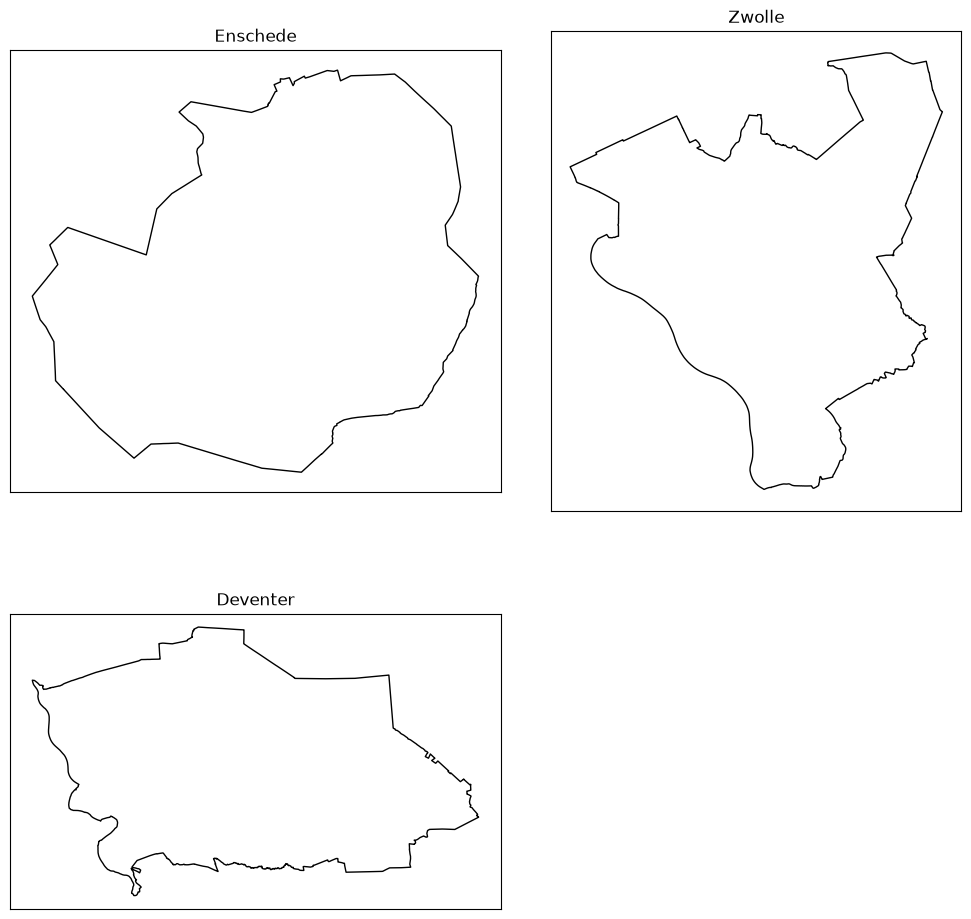

In [3]:
enschede = cities[
    cities['name']=='Enschede'
]

zwolle = cities[
    cities['name']=='Zwolle'
]

deventer = cities[
    cities['name']=='Deventer'
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(10,10),
    constrained_layout=True
)

axes = axes.flatten()

cities_dict = {
    'Enschede': enschede,
    'Zwolle': zwolle,
    'Deventer': deventer
}

for (city, gdf), ax in zip(cities_dict.items(), axes):

    gdf.plot(
        ax=ax,
        color='none'
    )

    ax.set(
        title=city,
        xlabel='',
        ylabel='',
        xticks=[],
        yticks=[]
    )

for ax in axes[len(cities_dict): ]:
    ax.remove()

plt.show()    

In [4]:
n_hoods = gpd.read_file(n_hoods_path, layer='buurten')
n_hoods.head(1)

,jrstatcode,bu_code,bu_naam,jrwk,wk_code,wk_naam,jrgm,gm_code,gm_naam,water,jaar,geometry
0,2026BU00140000,BU00140000,Binnenstad-Noord,2026WK001400,WK001400,Centrum,2026GM0014,GM0014,Groningen,NEE,2026,"MULTIPOLYGON Z (((233836.216 582380.178 0, 233..."


In [5]:
n_hood_stats = pd.read_excel('../data/inputs/kwb_2025.xlsx')
n_hood_stats.head()

,gwb_code_10,gwb_code_8,regio,gm_naam,recs,gwb_code,ind_wbi,a_inw,a_man,a_vrouw,...,g_afs_kv,g_afs_sc,g_3km_sc,a_opp_ha,a_lan_ha,a_wat_ha,pst_mvp,pst_dekp,ste_mvs,ste_oad
0,NL00,0000,Nederland,Nederland,Land,NL00,.,18044027,8978451,9065576,...,0.7,0.8,9.8,4154337,3364723,789614,NaN,NaN,2,2082
1,GM0014,0014,Groningen,Groningen,Gemeente,GM0014,1,244441,121379,123062,...,0.6,0.8,8.9,19796,18553,1244,NaN,NaN,1,3487
2,WK001400,001400,Centrum,Groningen,Wijk,WK001400,1,24980,12790,12185,...,0.5,0.8,14.1,241,228,13,NaN,NaN,1,6823
3,BU00140000,00140000,Binnenstad-Noord,Groningen,Buurt,BU00140000,1,4765,2495,2270,...,0.6,0.5,15.1,39,37,2,9712,1,1,7062
4,BU00140001,00140001,Binnenstad-Zuid,Groningen,Buurt,BU00140001,1,7085,3645,3440,...,0.5,0.9,13.3,59,55,4,9711,1,1,6765


In [6]:
n_hood_stats_gdf = pd.merge(
    n_hoods,
    n_hood_stats,
    left_on='bu_code',
    right_on='gwb_code_10'
).query(
    "gm_naam_y in ['Enschede', 'Zwolle', 'Deventer']"
)

n_hood_stats_gdf = n_hood_stats_gdf[[
    'bu_naam',
    'gm_naam_x',
    'a_inw',
    'geometry'
]]

n_hood_stats_gdf = n_hood_stats_gdf.rename(columns={
    'bu_naam': 'name',
    'gm_naam_x': 'city',
    'a_inw': 'population'
})

n_hood_stats_gdf['area_sqkm'] = round(
    (n_hood_stats_gdf.geometry.area / 10**6),
    2
)

n_hood_stats_gdf['pop_density'] = round(
    (n_hood_stats_gdf['population'] / (n_hood_stats_gdf.geometry.area / 10**6) ),
    2
)

n_hood_stats_gdf.head()

,name,city,population,geometry,area_sqkm,pop_density
1393,Centrum,Deventer,2950,"MULTIPOLYGON Z (((207422.705 474538.689 0, 207...",0.30,9893.18
1394,Bergkwartier,Deventer,670,"MULTIPOLYGON Z (((207874.87 474258.555 0, 2078...",0.09,7498.18
1395,Noordenbergkwartier,Deventer,820,"MULTIPOLYGON Z (((207280.043 474438.46 0, 2072...",0.07,12557.57
1396,Noordenbergsingel,Deventer,495,"MULTIPOLYGON Z (((207100.72 474629.09 0, 20710...",0.12,4205.89
1397,Singel,Deventer,1390,"MULTIPOLYGON Z (((207533.401 474840.566 0, 207...",0.37,3713.30


In [7]:
enschede_n_hoods = n_hood_stats_gdf[
    n_hood_stats_gdf['city']=='Enschede'
].drop(
    columns='city'
)

enschede_n_hoods.head()

,name,population,geometry,area_sqkm,pop_density
1462,City,3905,"MULTIPOLYGON Z (((258308 471708.09 0, 258316.0...",0.56,7031.34
1463,"Lasonder, Zeggelt",2030,"MULTIPOLYGON Z (((257725.75 472208.592 0, 2578...",0.29,7093.95
1464,De Laares,2440,"MULTIPOLYGON Z (((258844.192 472226.055 0, 258...",0.30,8119.99
1465,De Bothoven,5960,"MULTIPOLYGON Z (((259028.971 471678.53 0, 2591...",0.65,9213.42
1466,Hogeland-Noord,2995,"MULTIPOLYGON Z (((259026.93 470647.06 0, 25898...",0.35,8675.02


In [8]:
zwolle_n_hoods = n_hood_stats_gdf[
    n_hood_stats_gdf['city']=='Zwolle'
].drop(
    columns='city'
)

zwolle_n_hoods.head()

,name,population,geometry,area_sqkm,pop_density
2023,Binnenstad-Zuid,2370,"MULTIPOLYGON Z (((202684.313 503088.728 0, 202...",0.33,7114.45
2024,Binnenstad-Noord,1030,"MULTIPOLYGON Z (((202720.971 503207.074 0, 202...",0.12,8476.67
2025,Noordereiland,855,"MULTIPOLYGON Z (((203209.773 503415.475 0, 203...",0.15,5756.19
2026,Het Noorden,1735,"MULTIPOLYGON Z (((202850.801 503889.656 0, 202...",0.25,6924.04
2027,Schildersbuurt,345,"MULTIPOLYGON Z (((202902.064 503803.923 0, 202...",0.05,6328.39


In [9]:
deventer_n_hoods = n_hood_stats_gdf[
    n_hood_stats_gdf['city']=='Deventer'
].drop(
    columns='city'
)

deventer_n_hoods.head()

,name,population,geometry,area_sqkm,pop_density
1393,Centrum,2950,"MULTIPOLYGON Z (((207422.705 474538.689 0, 207...",0.30,9893.18
1394,Bergkwartier,670,"MULTIPOLYGON Z (((207874.87 474258.555 0, 2078...",0.09,7498.18
1395,Noordenbergkwartier,820,"MULTIPOLYGON Z (((207280.043 474438.46 0, 2072...",0.07,12557.57
1396,Noordenbergsingel,495,"MULTIPOLYGON Z (((207100.72 474629.09 0, 20710...",0.12,4205.89
1397,Singel,1390,"MULTIPOLYGON Z (((207533.401 474840.566 0, 207...",0.37,3713.30


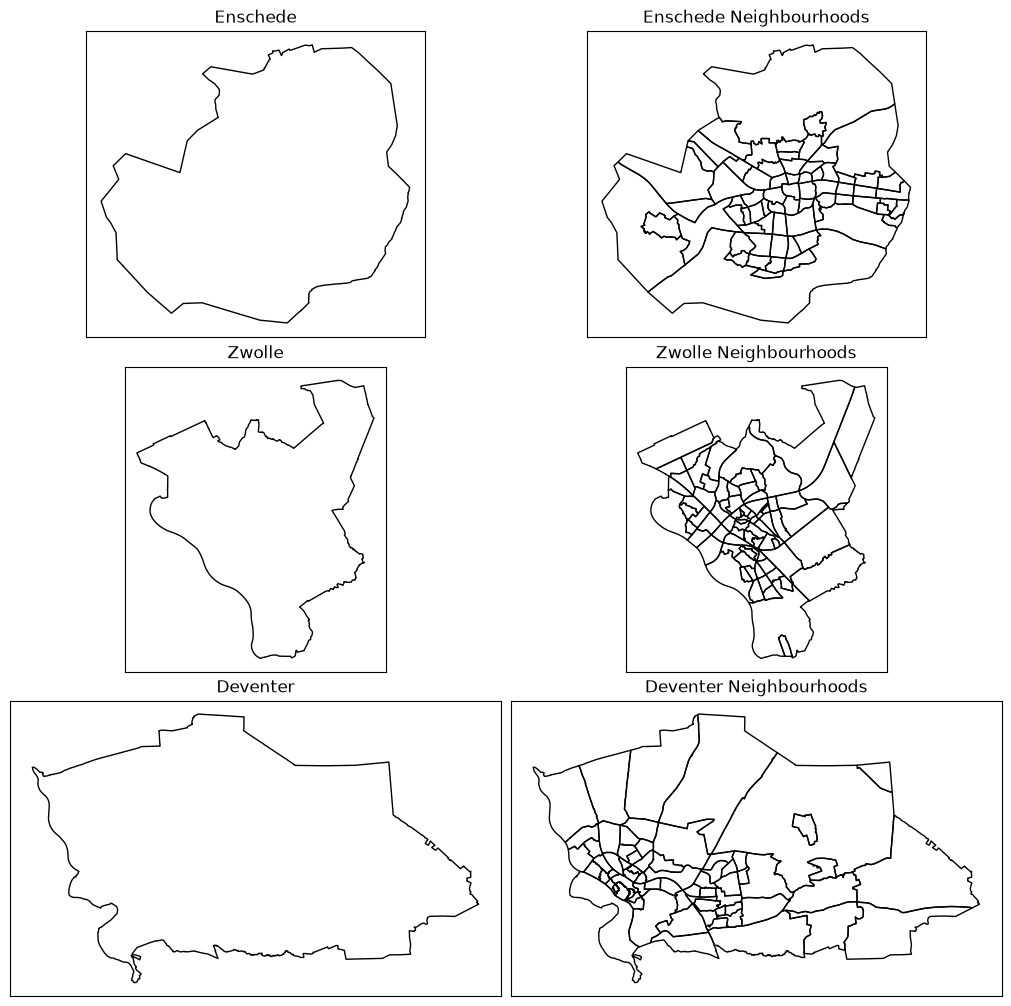

In [10]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(10,10),
    constrained_layout=True
)

axes = axes.flatten()

n_hood_dict = {
    'Enschede': enschede,
    'Enschede Neighbourhoods': enschede_n_hoods,
    'Zwolle': zwolle,
    'Zwolle Neighbourhoods': zwolle_n_hoods,
    'Deventer': deventer,
    'Deventer Neighbourhoods': deventer_n_hoods
}

for (city, gdf), ax in zip(n_hood_dict.items(), axes):

    gdf.plot(
        ax=ax,
        color='none'
    )

    ax.set(
        title=city,
        xlabel='',
        ylabel='',
        xticks=[],
        yticks=[]
    )

plt.show()

In [11]:
m = folium.Map(location=(52.21,6.89))
m

In [12]:
m.save('index.html')

In [13]:
m = folium.Map(
    location=(52.21, 6.89),
    zoom_start=12,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
    attr='Esri WorldStreetMap'
)

m

In [14]:
m = folium.Map()

c = folium.Choropleth(
    geo_data=enschede_n_hoods,
    data=enschede_n_hoods['pop_density'],
    key_on='feature.id',
    fill_color='RdYlGn_r',
    legend_name='Population Density (Inhabitants / km²)'
).add_to(m)

folium.GeoJson(
    enschede_n_hoods,
    zoom_on_click=True,
    style_function=lambda feature:{
        'fillOpacity': 0,
        'weight': 0
    },
    highlight_function=lambda feature: {
        'fillColor': 'black',
        'fillOpacity': 0.2,
        'color': 'black',
        'weight': 1
    },
    tooltip=folium.GeoJsonTooltip(
        fields=['name', 'pop_density'],
        aliases=['Name', 'Population Density'],
        localize=True
    )
).add_to(m)

m.fit_bounds(c.geojson.get_bounds())

m.save(map_export_path / 'enschede.html')
m

In [15]:
m = folium.Map()

c = folium.Choropleth(
    geo_data=zwolle_n_hoods,
    data=zwolle_n_hoods['pop_density'],
    key_on='feature.id',
    fill_color='RdYlGn_r',
    legend_name='Population Density (Inhabitants / km²)'
).add_to(m)

folium.GeoJson(
    zwolle_n_hoods,
    zoom_on_click=True,
    style_function=lambda feature:{
        'fillOpacity': 0,
        'weight': 0
    },
    highlight_function=lambda feature: {
        'fillColor': 'black',
        'fillOpacity': 0.2,
        'color': 'black',
        'weight': 1
    },
    tooltip=folium.GeoJsonTooltip(
        fields=['name', 'pop_density'],
        aliases=['Name', 'Population Density'],
        localize=True
    )
).add_to(m)

m.fit_bounds(c.geojson.get_bounds())

m.save(map_export_path / 'zwolle.html')
m

In [16]:
m = folium.Map()

c = folium.Choropleth(
    geo_data=deventer_n_hoods,
    data=deventer_n_hoods['pop_density'],
    key_on='feature.id',
    fill_color='RdYlGn_r',
    legend_name='Population Density (Inhabitants / km²)'
).add_to(m)

folium.GeoJson(
    deventer_n_hoods,
    zoom_on_click=True,
    style_function=lambda feature:{
        'fillOpacity': 0,
        'weight': 0
    },
    highlight_function=lambda feature: {
        'fillColor': 'black',
        'fillOpacity': 0.2,
        'color': 'black',
        'weight': 1
    },
    tooltip=folium.GeoJsonTooltip(
        fields=['name', 'pop_density'],
        aliases=['Name', 'Population Density'],
        localize=True
    )
).add_to(m)

m.fit_bounds(c.geojson.get_bounds())

m.save(map_export_path / 'deventer.html')
m

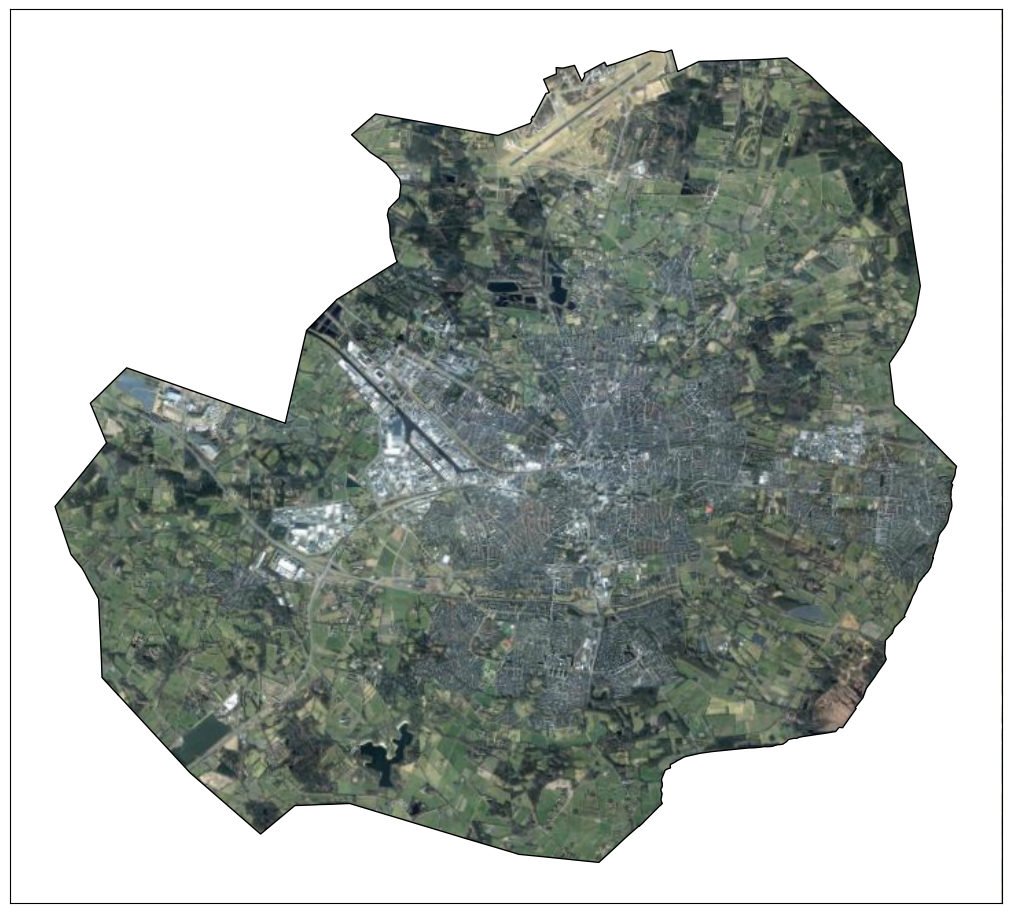

In [25]:
fig, ax = plt.subplots(
    figsize=(10,10),
    constrained_layout=True
)

enschede.plot(
    ax=ax,
    alpha=0
)

cx.add_basemap(
    ax=ax,
    crs=enschede.crs,
    source=cx.providers.Esri.WorldImagery,
    attribution=''
)

xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

plot_box = box(xmin, ymin, xmax, ymax)
inverse_plot = plot_box.difference(enschede.geometry)

inverse_plot.plot(
    ax=ax,
    color='white'
)

enschede.plot(
    ax=ax,
    color='none',
    edgecolor='black',
    linewidth=1
)

ax.set(
    xlabel='',
    ylabel='',
    xticks=[],
    yticks=[]
)

plt.savefig(
    image_export_path / 'enschede.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()